<a href="https://colab.research.google.com/github/smartypants85/SCUDEM-Hill-Model-RK4/blob/advanced_fit/fit_growth_strength.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
"""
Growth + strength fit, corrected using Wood et al. (2006) MRI data.

FIXES vs the original script (marked "FIX" below):
  1. Moment arm from MRI: d_r0 is solved from Wood's measured flexor moment arm at 90 deg,
     instead of DR0 = 0.03 (which gave r = 0.173 vs the measured 0.100).
  2. h0 = fitted upper-arm length at age 5 (was 0.24 m, longer than the arm itself).
  3. Forearm/upper-arm ratio from Wood's children (0.728 boys, 0.719 girls), not the adult 0.785.
  4. Force-length factor included: F_wrist = F_max * f_L * moment arm / lever. f_L uses rho,
     which is fit to the SHAPE of Wood's torque-vs-angle data (shape does not depend on F_max).
  (The growth fit itself is unchanged: same Euler step, so k and lambda_inf are the values already fitted.)

Unchanged: NHANES arm-length data, Daloia (2018) strength data, the logistic growth fit,
and the F_max0 * lambda^2 strength model.
"""
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, minimize_scalar

AGE0, DT, G = 5.0, 0.25, 9.81
AGES = np.arange(5, 15)  # strength data: ages 5..14

# NHANES 2021-2023 Table 17, upper arm length, 50th percentile (cm). Band midpoints.
UAL_AGES = np.array([5.0, 7.0, 9.0, 11.0, 13.0, 15.0, 17.0, 19.0, 24.5])  # last = adults 20-29 (Table 18)
UAL_CM = {
    "boys":  np.array([22.5, 26.0, 28.7, 31.8, 35.5, 37.9, 38.9, 38.5, 39.4]),
    "girls": np.array([22.3, 25.5, 28.1, 32.0, 34.2, 35.0, 35.4, 35.4, 35.9]),
}
ADULT_CHECK = {"boys": 39.4, "girls": 35.9}

# Daloia 2018 Appendix A, elbow flexors, dominant side, kgf, ages 5..14
STRENGTH_KGF = {
    "boys":  [6.59, 7.35, 9.14, 9.60, 9.88, 10.83, 11.97, 12.84, 14.22, 18.19],
    "girls": [7.35, 8.36, 7.68, 9.24, 10.01, 9.79, 9.01, 11.39, 12.16, 12.96],
}

# Wood et al. 2006 (9-10 y): age, flexor moment arm at 90 deg (mm), forearm/upper-arm ratio,
# isometric torque at 10/50/90 deg (N m, read from Fig. 2)
WOOD = {
    "boys":  dict(age=9.7, marm90_mm=20.9, fa_ratio=21.1 / 29.0, torque={10: 6.0, 50: 14.0, 90: 18.0}),
    "girls": dict(age=9.5, marm90_mm=20.2, fa_ratio=20.2 / 28.1, torque={10: 5.0, 50: 11.0, 90: 15.0}),
}
L_OPT0 = 0.07   # optimal fiber length at age 5 (m), as in the model


def lam_euler(k, linf, t_end=25.0):
    n = int(round((t_end - AGE0) / DT))
    lam = np.empty(n + 1)
    lam[0] = 1.0
    for i in range(n):
        lam[i + 1] = lam[i] + DT * k * lam[i] * (1 - lam[i] / linf)
    return lam


def lam_at(ages, k, linf):
    """Logistic growth by Euler (unchanged from the original fit). Off-grid ages are interpolated."""
    lam = lam_euler(k, linf)
    grid = AGE0 + DT * np.arange(len(lam))
    return np.interp(np.asarray(ages, dtype=float), grid, lam)


def fit_growth(ages, y):
    def f(a, k, linf, a5):
        return a5 * lam_at(a, k, linf)
    popt, pcov = curve_fit(f, ages, y, p0=[0.2, 1.6, y[0]],
                           bounds=([0.01, 1.05, 15.0], [2.0, 3.0, 30.0]))
    return popt, np.sqrt(np.diag(pcov)), f


def geometry(phi_deg, h, d_r, rho, l_opt):
    """Moment arm and force-length factor at elbow flexion phi (theta = phi - 90 deg)."""
    th = np.radians(phi_deg - 90.0)
    l_ts = np.sqrt(h ** 2 + d_r ** 2) - rho * l_opt          # tendon set by rho at theta = 0
    l_mt = np.sqrt(h ** 2 + d_r ** 2 - 2 * h * d_r * np.sin(th))
    d_m = h * d_r * np.cos(th) / l_mt
    f_L = np.exp(-(((l_mt - l_ts) / l_opt - 1) ** 2) / 0.45)
    return d_m, f_L


def fit_geometry(sex, k, linf, h0):
    """FIX 1, 2, 4: d_r0 from the MRI moment arm, rho from the torque-angle SHAPE."""
    w = WOOD[sex]
    L = lam_at(w["age"], k, linf)
    h = h0 * L
    a = w["marm90_mm"] / 1000
    d_r = a * h / np.sqrt(h ** 2 - a ** 2)                   # invert d_m(90 deg) = h d_r / sqrt(h^2 + d_r^2)
    d_r0 = d_r / L
    angles = np.array(sorted(w["torque"]))
    data = np.array([w["torque"][x] for x in angles])

    def shape_err(rho):
        d_m, f_L = geometry(angles, h, d_r, rho, L_OPT0 * L)
        m = d_m * f_L
        c = (m @ data) / (m @ m)                             # best scale (absorbs F_max)
        return np.sum((c * m - data) ** 2)
    rho = minimize_scalar(shape_err, bounds=(0.4, 2.0), method="bounded").x
    return d_r0, rho


def fit_force(k, linf, ual5_m, h0, d_r0, rho, fa_ratio, kgf):
    """F_wrist = F_max0 * lambda^2 * f_L(90 deg) * moment arm / forearm lever."""
    a_arm = h0 * d_r0 / np.sqrt(h0 ** 2 + d_r0 ** 2)         # moment arm at 90 deg flexion, age 5
    L_fa0 = fa_ratio * ual5_m                                # FIX 3: child forearm/upper-arm ratio
    f_L90 = np.exp(-((rho - 1) ** 2) / 0.45)                 # FIX 4: l_m = rho * l_opt at 90 deg
    r = a_arm / L_fa0                                        # mechanical advantage
    r_eff = r * f_L90

    def f(a, F0):
        return F0 * lam_at(a, k, linf) ** 2 * r_eff / G
    popt, pcov = curve_fit(f, AGES, kgf, p0=[300.0])
    return popt[0], float(np.sqrt(pcov[0, 0])), r, f_L90, f


if __name__ == "__main__":
    results = {}
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for j, sex in enumerate(["boys", "girls"]):
        y = UAL_CM[sex]
        (k, linf, a5), (ek, el, ea), fg = fit_growth(UAL_AGES, y)
        rmse_h = np.sqrt(np.mean((fg(UAL_AGES, k, linf, a5) - y) ** 2))
        h0 = a5 / 100                                        # FIX 2
        d_r0, rho = fit_geometry(sex, k, linf, h0)
        F0, eF0, r, fL90, ff = fit_force(k, linf, a5 / 100, h0, d_r0, rho, WOOD[sex]["fa_ratio"],
                                         np.array(STRENGTH_KGF[sex]))
        pred = ff(AGES, F0)
        rmse_f = np.sqrt(np.mean((pred - np.array(STRENGTH_KGF[sex])) ** 2))
        l_ts0 = np.sqrt(h0 ** 2 + d_r0 ** 2) - rho * L_OPT0
        results[sex] = dict(k=k, ek=ek, linf=linf, el=el, ual5_cm=a5, h0=h0, d_r0=d_r0, rho=rho,
                            l_ts0=l_ts0, F0=F0, eF0=eF0, r=r, f_L90=fL90,
                            rmse_arm_cm=rmse_h, rmse_force_kgf=rmse_f, F_adult=F0 * linf ** 2)
        print(f"\n=== {sex} ===")
        print(f"k        = {k:.4f} +/- {ek:.4f}")
        print(f"lam_inf  = {linf:.4f} +/- {el:.4f}")
        print(f"arm(5)   = {a5:.2f} cm; fitted adult arm = {a5 * linf:.1f} cm vs NHANES adult 20-29 = "
              f"{ADULT_CHECK[sex]} cm;  arm RMSE = {rmse_h:.2f} cm")
        print(f"h0       = {h0:.4f} m   d_r0 = {d_r0 * 1000:.1f} mm   rho = {rho:.3f}   l_ts0 = {l_ts0:.4f} m")
        print(f"r        = {r:.3f} (Wood MRI: {WOOD[sex]['marm90_mm'] / 10 / (WOOD[sex]['fa_ratio'] * a5 * lam_at(WOOD[sex]['age'], k, linf)):.3f} at 90 deg)"
              f"   f_L(90 deg) = {fL90:.3f}")
        print(f"F_max0   = {F0:.1f} +/- {eF0:.1f} N;  strength RMSE = {rmse_f:.2f} kgf;  "
              f"implied adult F_max = {F0 * linf ** 2:.0f} N")

        tt = np.linspace(5, 25, 81)
        ax = axes[0, j]
        ax.scatter(UAL_AGES, y, label="NHANES median upper arm length (last pt = adults)")
        ax.plot(tt, a5 * lam_at(tt, k, linf), "r", label="logistic fit (k, lam_inf)")
        ax.set(title=f"{sex}: arm length", xlabel="age (yr)", ylabel="upper arm length (cm)"); ax.legend(fontsize=8)
        ax = axes[1, j]
        ax.scatter(AGES, STRENGTH_KGF[sex], label="data (kgf at wrist)")
        t2 = tt[tt <= 14.01]
        ax.plot(t2, ff(t2, F0), "r", label="F_max0*lam^2 fit (MRI moment arm)")
        ax.set(title=f"{sex}: elbow flexion force", xlabel="age (yr)", ylabel="kgf"); ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig("growth_strength_fit.png", dpi=130)
    pd.DataFrame(results).T.to_csv("fitted_params.csv")
    print("\nSaved growth_strength_fit.png and fitted_params.csv")



=== boys ===
k        = 0.2069 +/- 0.0257
lam_inf  = 1.8575 +/- 0.0626
arm(5)   = 21.90 cm; fitted adult arm = 40.7 cm vs NHANES adult 20-29 = 39.4 cm;  arm RMSE = 0.73 cm
h0       = 0.2190 m   d_r0 = 14.9 mm   rho = 0.709   l_ts0 = 0.1699 m
r        = 0.093 (Wood MRI: 0.093 at 90 deg)   f_L(90 deg) = 0.828
F_max0   = 736.5 +/- 23.5 N;  strength RMSE = 1.10 kgf;  implied adult F_max = 2541 N

=== girls ===
k        = 0.2460 +/- 0.0275
lam_inf  = 1.6760 +/- 0.0453
arm(5)   = 21.76 cm; fitted adult arm = 36.5 cm vs NHANES adult 20-29 = 35.9 cm;  arm RMSE = 0.55 cm
h0       = 0.2176 m   d_r0 = 14.7 mm   rho = 0.793   l_ts0 = 0.1626 m
r        = 0.094 (Wood MRI: 0.094 at 90 deg)   f_L(90 deg) = 0.909
F_max0   = 603.7 +/- 24.6 N;  strength RMSE = 1.21 kgf;  implied adult F_max = 1696 N

Saved growth_strength_fit.png and fitted_params.csv


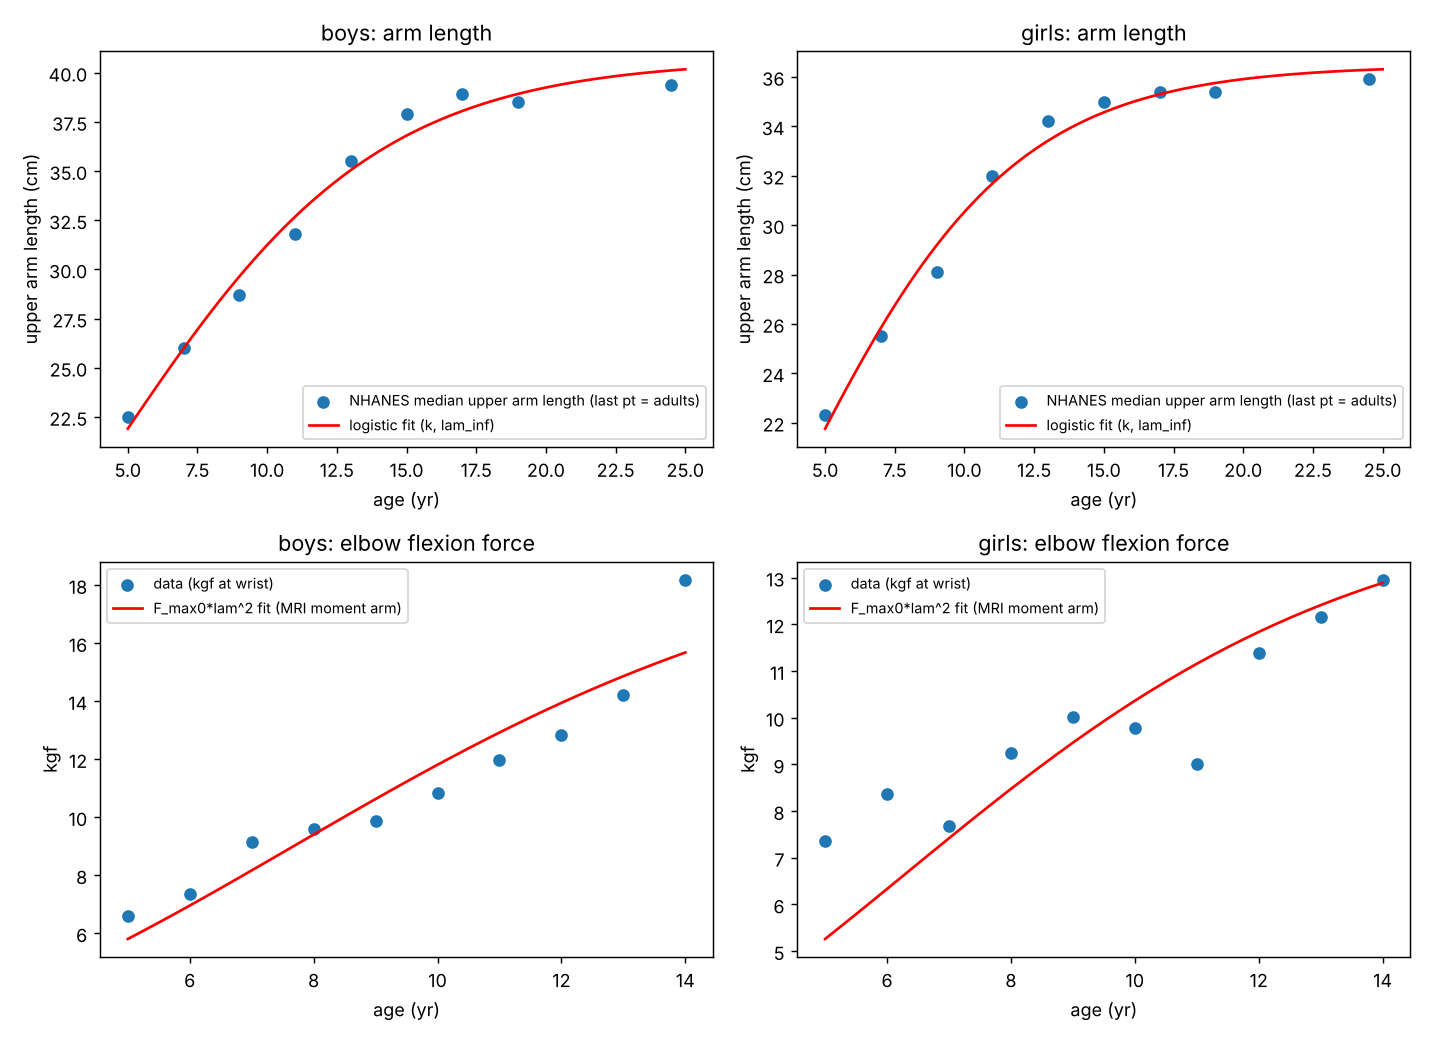

In [ ]:
from IPython.display import Image
Image('growth_strength_fit.png')
